# 05 — Roofline atlas

**Question.** Where do the measured compute and bandwidth ceilings meet for each precision and memory configuration, and where do achieved kernels sit relative to them?

Line style tells the origin of a ceiling: **dashed** = theoretical (vendor or derived), **solid** = best measured by a dedicated kernel, **dotted** = what a library kernel (oneDNN GEMM) achieved. Memory slopes use the best sustained of Triad, non-temporal Triad and read-only (ERT convention) unless a figure says otherwise: the GEMM figures use the read-only ceiling (weights are only read) and the FP64 sweep uses the best read/write kernel (it loads one array and stores another). Bytes are modeled, so these are empirical envelopes, not counter-based bounds. Section 6 lists every point that lies above its own roofline.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/hwbench').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from hwbench import report, roofline, plotting
from hwbench.notebook import setup
ctx = setup('05_roofline_atlas')
thesis, ext, theory = ctx.thesis, ctx.ext, ctx.theory
table, figure, say, say_claims = ctx.table, ctx.figure, ctx.say, ctx.say_claims
from hwbench import claims

In [2]:
PATHS = ['fp64', 'fp32', 'avx512_bf16', 'vnni_int8', 'amx_bf16', 'amx_int8']
def compute_set(mode, scope, cores):
    out = [report.compute_ceiling(ext, p, mode, cores, scope) for p in PATHS]
    return out
def theory_set(paths, scope, cores):
    return [report.theoretical_ceiling(theory, p, cores, scope) for p in paths]

## 1. Flat mode, one socket (56 cores)

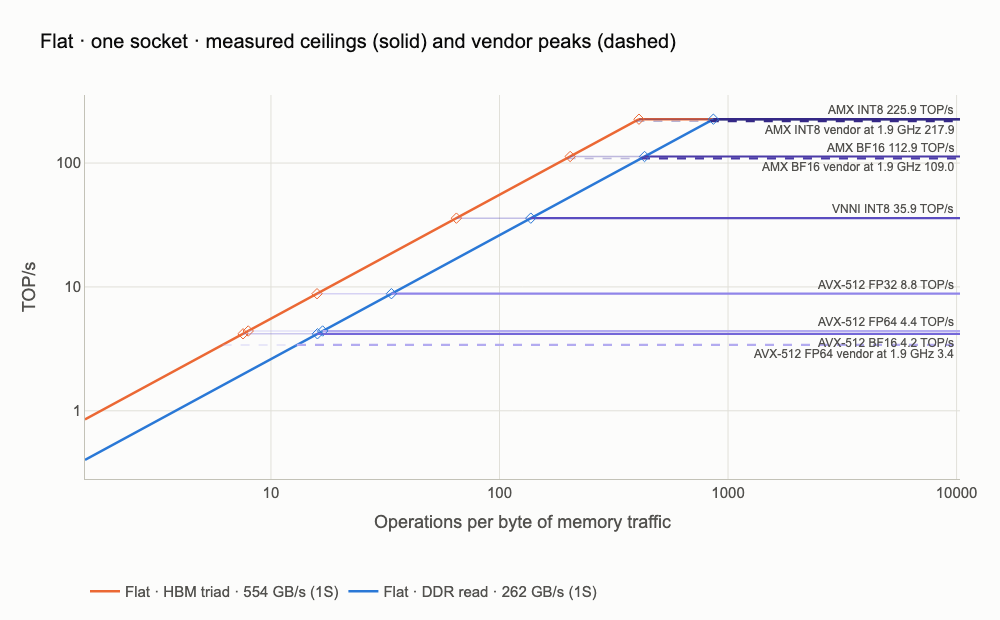

Saved figures/05_roofline_atlas/atlas_flat_1s.svg and .png


memory,GBs,fp64,fp32,avx512_bf16,vnni_int8,amx_bf16,amx_int8
hbm (triad),554.213,7.955,15.908,7.549,64.789,203.794,407.648
ddr (read),261.923,16.832,33.660,15.973,137.089,431.216,862.559


In [3]:
mem = [report.memory_ceiling(ext, thesis, 'flat', 'hbm'), report.memory_ceiling(ext, thesis, 'flat', 'ddr')]
fig = plotting.roofline_figure(theory_set(['fp64', 'amx_bf16', 'amx_int8'], '1S', 56) + compute_set('flat', '1S', 56), mem,
                               title='Flat · one socket · measured ceilings (solid) and vendor peaks (dashed)')
figure(fig, 'atlas_flat_1s')
table(pd.DataFrame([dict(memory=f'{m.tier} ({m.kernel})', GBs=m.gbs, **{p: roofline.ridge(c.gops, m.gbs) for p, c in zip(PATHS, compute_set('flat', '1S', 56))}) for m in mem]))

The table gives the **ridge** (operations per byte) at which each path stops being memory-bound. Higher-throughput paths need proportionally more reuse; the ridge values for HBM and DDR are stated below.

In [4]:
say_claims(claims.ridges(ext, thesis, theory), ['ridge_points'])

* On HBM (554 GB/s, triad) the ridge is 8.0 FLOP/B for FP64, 204 op/B for AMX BF16 and 408 op/B for AMX INT8; on DDR (262 GB/s, read) 16.8, 431 and 863. Ridge points are order-of-magnitude statements: bytes are modeled and the HBM ceiling is a 56-core figure.

## 2. Cache mode, one socket

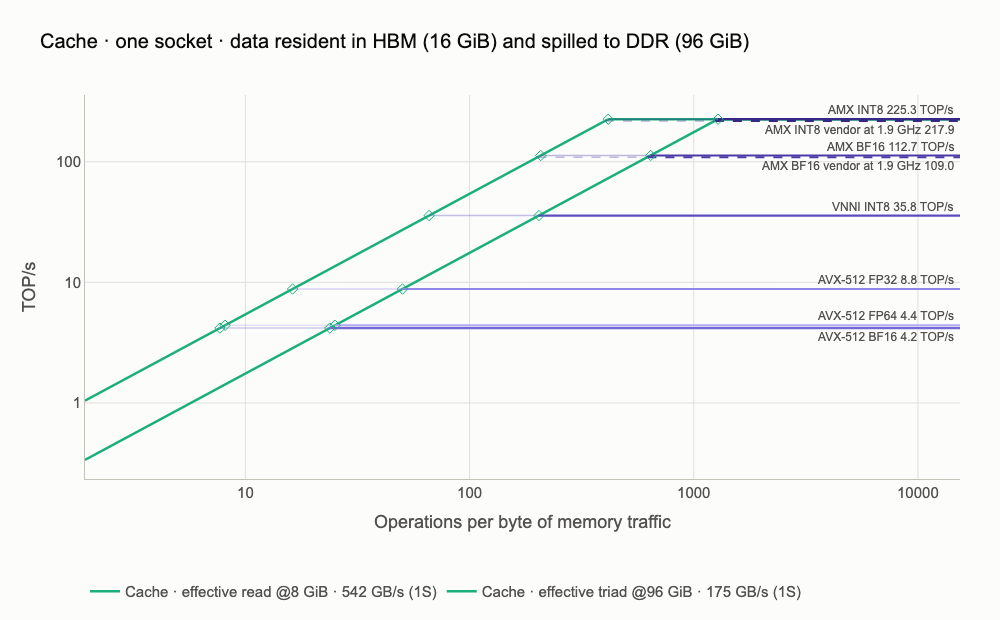

Saved figures/05_roofline_atlas/atlas_cache_1s.svg and .png


case,kernel,GBs,working_set_gib
effective_cache,read,542.216,8.000
effective_cache,triad,175.416,96.000


In [5]:
resident = report.memory_ceiling(ext, thesis, 'cache', 'effective_cache', resident_gib=16)
spilled = report.memory_ceiling(ext, thesis, 'cache', 'effective_cache', at_gib=96)
fig = plotting.roofline_figure(theory_set(['amx_bf16', 'amx_int8'], '1S', 56) + compute_set('cache', '1S', 56), [resident, spilled],
                               title='Cache · one socket · data resident in HBM (16 GiB) and spilled to DDR (96 GiB)')
figure(fig, 'atlas_cache_1s')
table(pd.DataFrame([dict(case=c.tier, kernel=c.kernel, GBs=c.gbs, working_set_gib=c.working_set_gib) for c in (resident, spilled)]))

In [6]:
say_claims(claims.cache_mode(ext, thesis), ['cache_declines_before_capacity', 'cache_triad_spilled_ceiling'])

* Cache-mode Triad declines with working set from 8 GiB onward (491, 478, 371, 287, 241 GB/s at 8, 16, 32, 48, 64 GiB). Against Flat HBM Triad (554 GB/s) it retains 86% at 16, 67% at 32, 52% at 48, 43% at 64 GiB. Cache mode therefore does **not** match Flat HBM while the working set fits in the 64 GiB memory-side cache. A direct-mapped cache with conflict misses would behave like this; that is an inference, because no cache hit-rate counter is readable.
* The best kernel at 96 GiB is Triad (175 GB/s), +21% against non-temporal Triad (145) and +79% against read-only (98); the spilled ceiling uses it (best of the three kernels, as for every other ceiling).

Every ridge moves right by the ratio of the two slopes. The 16 GiB line is the best case for a model of that size; the 96 GiB line is the Triad-based ceiling of the spilled case.

## 3. Flat mode, both sockets

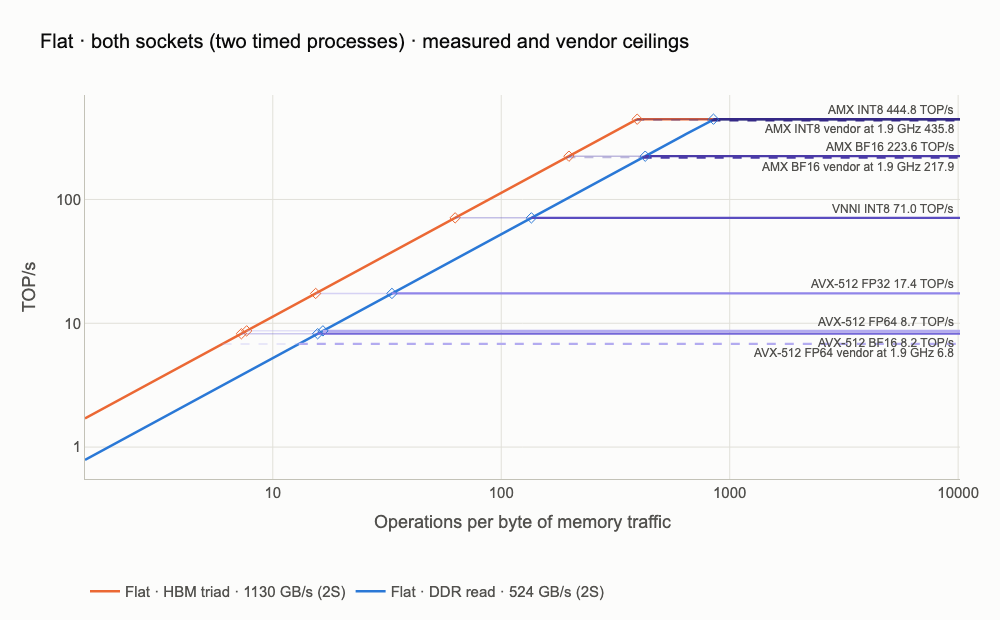

Saved figures/05_roofline_atlas/atlas_flat_2s.svg and .png


In [7]:
mem2 = [report.memory_ceiling(ext, thesis, 'flat', 'hbm', '2S'), report.memory_ceiling(ext, thesis, 'flat', 'ddr', '2S')]
fig = plotting.roofline_figure(theory_set(['fp64', 'amx_bf16', 'amx_int8'], '2S', 56) + compute_set('flat', '2S', 56), mem2,
                               title='Flat · both sockets (two timed processes) · measured and vendor ceilings')
figure(fig, 'atlas_flat_2s')

In [8]:
say_claims(claims.ridges(ext, thesis, theory), ['ridge_points', 'two_sockets_ridge'])

* On HBM (554 GB/s, triad) the ridge is 8.0 FLOP/B for FP64, 204 op/B for AMX BF16 and 408 op/B for AMX INT8; on DDR (262 GB/s, read) 16.8, 431 and 863. Ridge points are order-of-magnitude statements: bytes are modeled and the HBM ceiling is a 56-core figure.
* Two sockets multiply the compute ceilings by 1.97 (FP64) and 1.98 (AMX BF16) and the HBM bandwidth ceiling by 2.04 (DDR 2.00), so HBM ridge points move by -3.4% (FP64) and -2.9% (AMX BF16): essentially unchanged, because socket 1's HBM ceiling is a little higher than socket 0's.

## 4. Achieved points: FP64 sweep

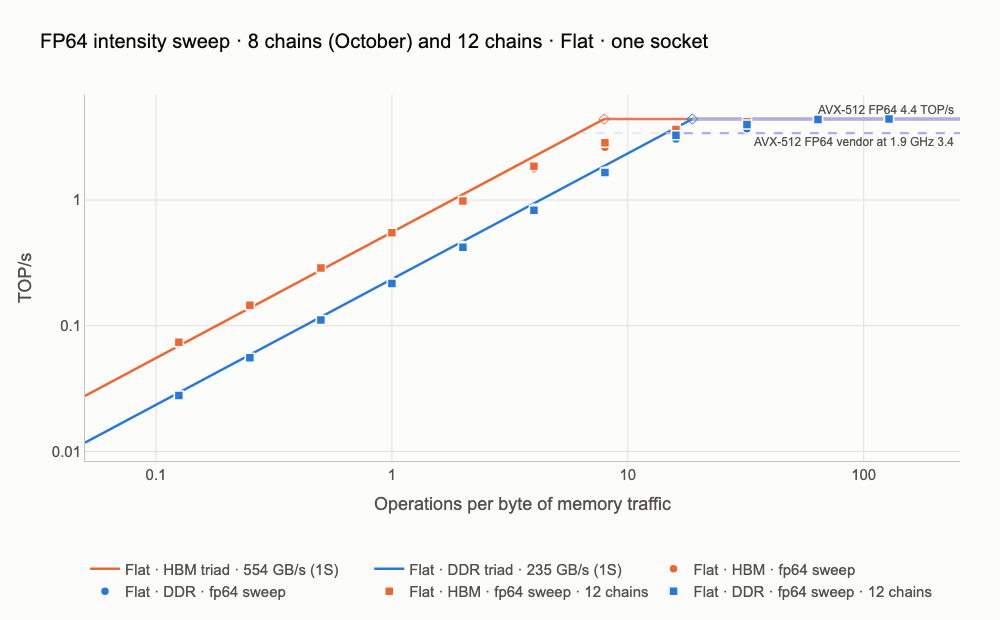

Saved figures/05_roofline_atlas/atlas_fp64_sweep.svg and .png


* With 12 independent FMA chains the FP64 sweep reaches 99.1% of the measured FP64 peak at 64 FLOP/B and 100.1% at 128 FLOP/B (DDR: 100.2%); the 8-chain kernel of the earlier campaign stops at 87.8% (control at K = 1024). The earlier shortfall was the kernel's chain count, not the hardware.
* Near the ridge the cores run slower: at 8 FLOP/B on HBM the effective clock is 1.74 GHz against 2.48 GHz at high intensity, so the sweep sits at 65% of the peak but 92% of the peak at that clock. The dip around the ridge is mostly the clock drop under HBM streaming (cause not measured), not a kernel limit.

In [9]:
flat_hbm, flat_ddr = mem
fp64 = [report.compute_ceiling(ext, 'fp64', 'flat', 56)]
mem_rw = [report.memory_ceiling(ext, thesis, 'flat', 'hbm', access='readwrite'), report.memory_ceiling(ext, thesis, 'flat', 'ddr', access='readwrite')]
pts = report.fp64_sweep_points(thesis, 'flat', 'hbm') + report.fp64_sweep_points(thesis, 'flat', 'ddr')
pts12 = report.fp64_sweep12_points(ext, thesis, theory, 'hbm') + report.fp64_sweep12_points(ext, thesis, theory, 'ddr')
audits = [roofline.audit_points(pts, mem_rw, fp64).assign(group='FP64 sweep · Flat · read/write ceiling'),
          roofline.audit_points(pts12, mem_rw, fp64).assign(group='FP64 sweep, 12 chains · Flat · read/write ceiling')]
fig = plotting.roofline_figure(fp64 + theory_set(['fp64'], '1S', 56), mem_rw, pts + pts12, title='FP64 intensity sweep · 8 chains (October) and 12 chains · Flat · one socket', x_range=(0.05, 256))
figure(fig, 'atlas_fp64_sweep')
hb = [p for p in pts if p.memory_target == 'hbm']
say_claims(claims.fp64_sweep(ext, thesis, theory))

## 5. Achieved points: BF16 and INT8 GEMM

Each point is one (shape, M) pair. Intensity rises with M because the same weights are reused for more tokens; the point leaves the memory slope when the GEMM becomes compute-limited.

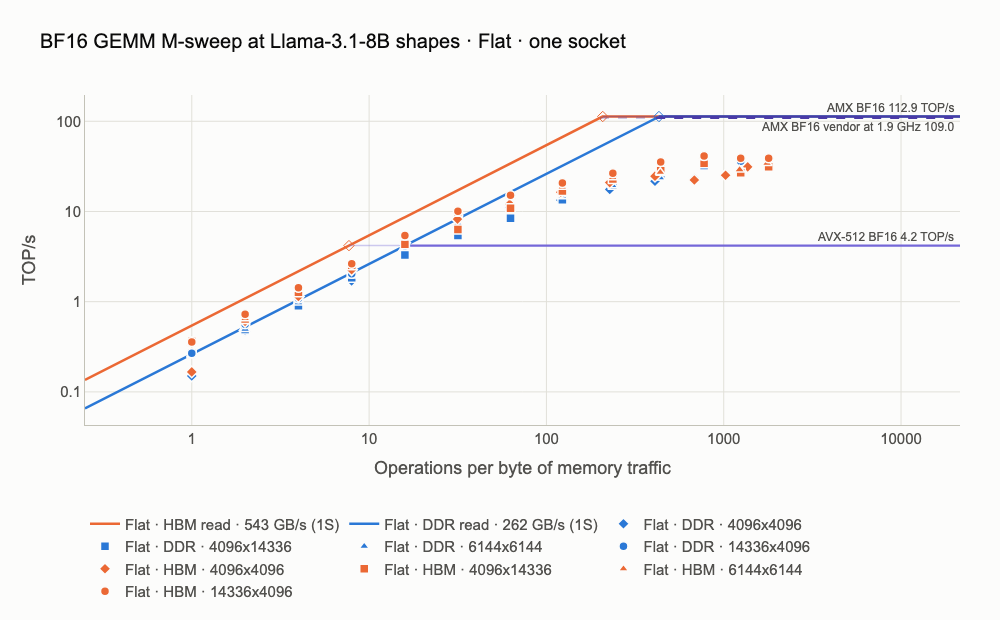

Saved figures/05_roofline_atlas/atlas_gemm_bf16.svg and .png


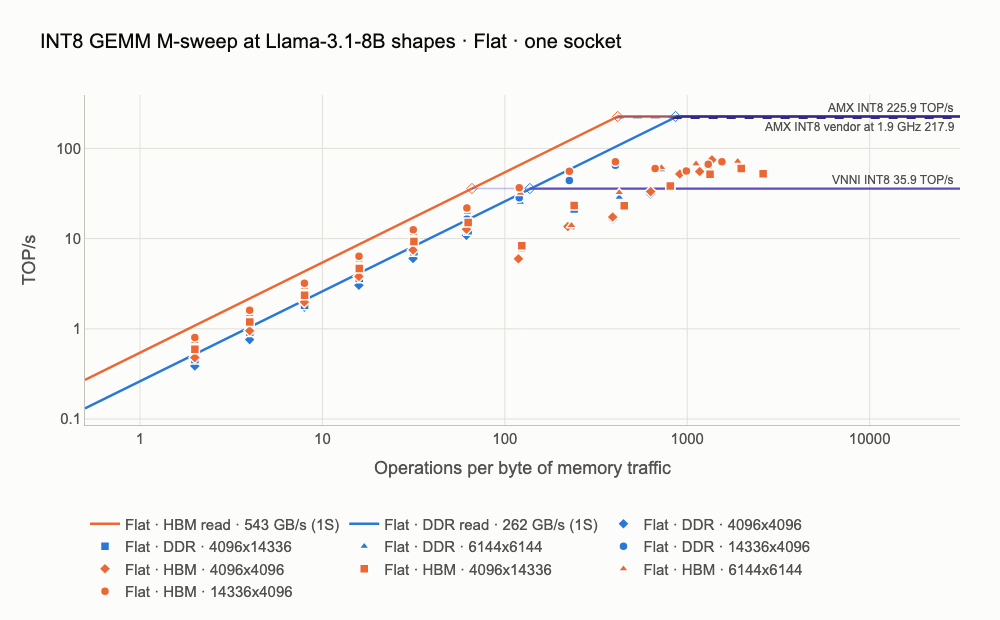

Saved figures/05_roofline_atlas/atlas_gemm_int8.svg and .png


In [10]:
gm = report.gemm_points(ext)
mem_read = [report.memory_ceiling(ext, thesis, 'flat', 'hbm', access='read'), report.memory_ceiling(ext, thesis, 'flat', 'ddr', access='read')]
for dtype, path in [('bf16', 'amx_bf16'), ('int8', 'amx_int8')]:
    sel = gm[(gm.memory_mode == 'flat') & (gm.dtype == dtype)]
    pts = report.gemm_workload_points(sel, theory)
    cs = [report.compute_ceiling(ext, path, 'flat', 56), report.theoretical_ceiling(theory, path, 56)]
    if dtype == 'bf16':
        cs.append(report.compute_ceiling(ext, 'avx512_bf16', 'flat', 56))
    else:
        cs.append(report.compute_ceiling(ext, 'vnni_int8', 'flat', 56))
    audits.append(roofline.audit_points(pts, mem_read, cs).assign(group=f'{dtype.upper()} GEMM · Flat · read-only ceiling'))
    fig = plotting.roofline_figure(cs, mem_read, pts, title=f'{dtype.upper()} GEMM M-sweep at Llama-3.1-8B shapes · Flat · one socket')
    figure(fig, f'atlas_gemm_{dtype}')

In [11]:
rows = []
for dtype, path in [('bf16', 'amx_bf16'), ('int8', 'amx_int8')]:
    peak = report.compute_ceiling(ext, path, 'flat', 56).gops
    theo = theory.peak_gops(path, 56)
    for tgt, bw in [('hbm', flat_hbm.gbs), ('ddr', flat_ddr.gbs)]:
        sel = gm[(gm.memory_mode == 'flat') & (gm.dtype == dtype) & (gm.memory_target == tgt)]
        best = sel.loc[sel.gops.idxmax()]
        rows.append(dict(dtype=dtype, memory=tgt, best_shape=best['shape'], best_M=int(best.m), achieved_TOPs=best.gops / 1000,
                         measured_tile_peak_TOPs=peak / 1000, theory_TOPs=theo / 1000,
                         achieved_over_measured=best.gops / peak, measured_over_theory=peak / theo, achieved_over_theory=best.gops / theo))
gap = pd.DataFrame(rows)
table(gap)

dtype,memory,best_shape,best_M,achieved_TOPs,measured_tile_peak_TOPs,theory_TOPs,achieved_over_measured,measured_over_theory,achieved_over_theory
bf16,hbm,14336x4096,1024,41.135,112.945,108.954,0.364,1.037,0.378
bf16,ddr,14336x4096,1024,38.068,112.945,108.954,0.337,1.037,0.349
int8,hbm,4096x4096,4096,74.622,225.924,217.907,0.330,1.037,0.342
int8,ddr,4096x4096,4096,75.826,225.924,217.907,0.336,1.037,0.348


### Counted against modeled intensity

The cores' DRAM counters give the intensity a point actually has. Each BF16 and INT8 point of the 14336×4096 projection appears twice, with modeled and with counted bytes, at the same rate.

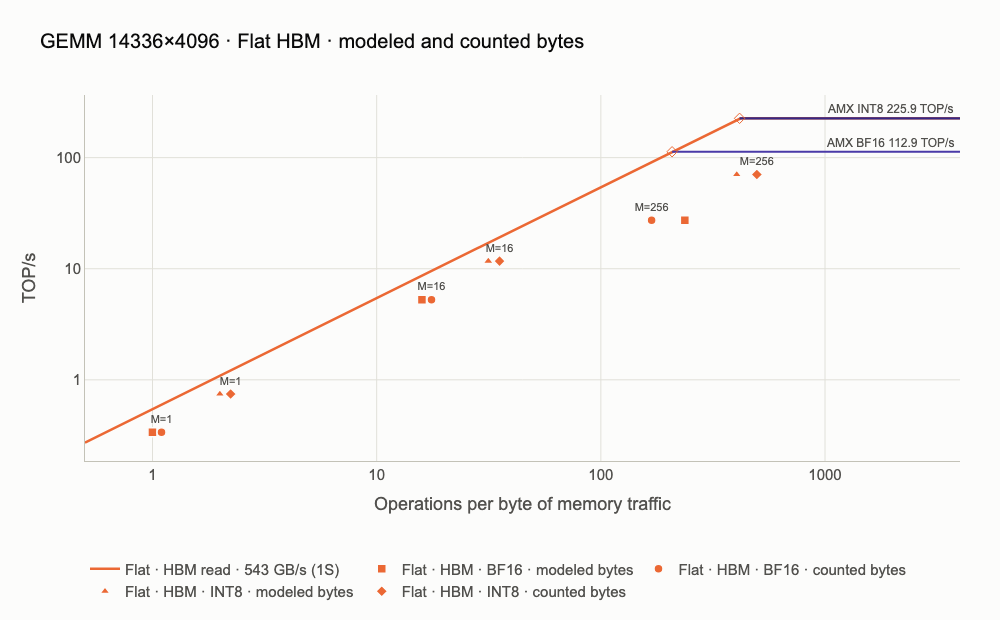

Saved figures/05_roofline_atlas/atlas_counted_gemm.svg and .png


* The weights of the first GEMM sweep were partly served on chip: with a pool of about 1 GB (Flat) the cores read 89%–91% of the modeled bytes at M ≤ 16, against 99%–100% with a 16 GiB pool in Cache mode. Modeled bandwidth therefore overstated the Flat GEMM traffic by about 10% at small M.
* At M=256 the weights-only model misses traffic that BF16 moves and INT8 does not: BF16 counts 1.37–1.41× the modeled bytes (counted read share 0.87–0.88: activations, outputs and repacking), INT8 0.81–0.83×. On a roofline the BF16 prefill points move left, from 237 to 168 operations per byte, when counted bytes are used.

In [12]:
cs = [report.compute_ceiling(ext, p, 'flat', 56) for p in ('amx_bf16', 'amx_int8')]
fig = plotting.roofline_figure(cs, [mem_read[0]], report.counted_gemm_points(ext, theory, 'hbm'), title='GEMM 14336×4096 · Flat HBM · modeled and counted bytes', point_labels=True, x_range=(0.5, 4000))
figure(fig, 'atlas_counted_gemm')
say_claims(claims.counted(ext, thesis), ['counted_gemm_weights', 'counted_gemm_prefill'])

**Gap analysis.** Two layers separate the vendor number from library performance: (1) the vendor peak versus what a hand-written tile kernel sustains (the clock the cores actually ran at; compare `measured_over_theory` below); (2) the tile-kernel peak versus an optimized library GEMM (the achieved-over-measured column).

## 6. Ceiling audit: points above their own roofline

A ceiling is only an upper bound if no accepted point lies above it. Each point below is compared with `min(compute ceiling, bandwidth ceiling × intensity)` for its own tier and ISA path; it counts as *exceeding* when it is above that bound by more than the larger of its own and the ceiling's run-to-run spread (CV). Cache-mode GEMM uses the best-kernel ceiling at the pool size of the run (16 GiB resident, 96 GiB spilled).

In [13]:
for pool, ceiling in [(16, resident), (96, spilled)]:
    for dtype, path in [('bf16', 'amx_bf16'), ('int8', 'amx_int8')]:
        sel = gm[(gm.memory_mode == 'cache') & (gm.dtype == dtype) & ((gm.pool_gib - pool).abs() < 0.5)]
        audits.append(roofline.audit_points(report.gemm_workload_points(sel, theory), [ceiling], compute_set('cache', '1S', 56)).assign(group=f'{dtype.upper()} GEMM · Cache · {pool} GiB pool · best-kernel ceiling'))
audits.append(roofline.audit_points(report.gemm_pool_points(ext, 64), mem_read, [report.compute_ceiling(ext, p, 'flat', 56) for p in ('amx_bf16', 'amx_int8')]).assign(group='GEMM · Flat · 64× pool · read-only ceiling'))
audit = pd.concat(audits, ignore_index=True)
summary = audit.groupby('group').agg(points=('exceeds', 'size'), exceeding=('exceeds', 'sum'), max_ratio=('ratio', 'max')).reset_index()
table(summary)
say(f"**Result.** {int(audit.exceeds.sum())} of {len(audit)} points lie above their roofline by more than their spread; the largest excess is {audit.ratio.max() - 1:.1%}.")
table(audit[audit.exceeds].sort_values('ratio', ascending=False)[['group', 'series', 'intensity', 'bandwidth_gbs', 'ceiling_gbs', 'ceiling_kernel', 'ratio', 'tolerance_percent']])

group,points,exceeding,max_ratio
BF16 GEMM · Cache · 16 GiB pool · best-kernel ceiling,28,0,0.570
BF16 GEMM · Cache · 96 GiB pool · best-kernel ceiling,28,0,0.977
BF16 GEMM · Flat · read-only ceiling,104,4,1.074
FP64 sweep · Flat · read/write ceiling,18,3,1.036
"FP64 sweep, 12 chains · Flat · read/write ceiling",22,3,1.066
GEMM · Flat · 64× pool · read-only ceiling,12,0,0.869
INT8 GEMM · Cache · 16 GiB pool · best-kernel ceiling,28,0,0.539
INT8 GEMM · Cache · 96 GiB pool · best-kernel ceiling,24,0,0.878
INT8 GEMM · Flat · read-only ceiling,104,7,1.085


**Result.** 17 of 368 points lie above their roofline by more than their spread; the largest excess is 8.5%.

group,series,intensity,bandwidth_gbs,ceiling_gbs,ceiling_kernel,ratio,tolerance_percent
INT8 GEMM · Flat · read-only ceiling,14336x4096,3.992,284.239,261.923,read,1.085,0.609
INT8 GEMM · Flat · read-only ceiling,14336x4096,15.867,281.997,261.923,read,1.077,0.398
BF16 GEMM · Flat · read-only ceiling,14336x4096,1.999,281.201,261.923,read,1.074,1.517
INT8 GEMM · Flat · read-only ceiling,14336x4096,1.998,281.089,261.923,read,1.073,0.589
INT8 GEMM · Flat · read-only ceiling,14336x4096,7.967,280.308,261.923,read,1.070,0.761
INT8 GEMM · Flat · read-only ceiling,14336x4096,31.473,279.788,261.923,read,1.068,0.672
"FP64 sweep, 12 chains · Flat · read/write ceiling",fp64 sweep · 12 chains,0.125,590.775,554.213,triad,1.066,1.909
"FP64 sweep, 12 chains · Flat · read/write ceiling",fp64 sweep · 12 chains,0.250,583.310,554.213,triad,1.053,3.023
"FP64 sweep, 12 chains · Flat · read/write ceiling",fp64 sweep · 12 chains,0.500,575.249,554.213,triad,1.038,3.421
FP64 sweep · Flat · read/write ceiling,fp64 sweep,0.125,574.099,554.213,triad,1.036,1.112


**Reading the exceptions.** They are listed, not hidden. Two mechanisms can raise a point above a kernel-based ceiling: the access pattern differs from every ceiling kernel, or the modeled bytes overcount real traffic. The counters and the pool sweep tell them apart:

In [14]:
g64 = audit[audit.group.str.contains('64× pool')]
say(f"**Result.** With the converged 64× pool {int(g64.exceeds.sum())} of {len(g64)} GEMM points lie above their roofline.")
say_claims(claims.gemm(ext, thesis, theory, ROOT), ['gemm_pool_convergence'])
say_claims(claims.counted(ext, thesis), ['counted_gemm_weights', 'sweep_exceeds_triad_ceiling'])

**Result.** With the converged 64× pool 0 of 12 GEMM points lie above their roofline.

* The weight pool of the first GEMM campaign (about 2× the on-chip capacity) was too small: even a 4× pool leaves the counted DRAM traffic below the modeled one at M=1, and the modeled bandwidth falls as the pool grows (DDR BF16 14336×4096: 239, 228, 226 GB/s at 4×, 16×, 64× the on-chip capacity; HBM 335, 323, 324). Counted bandwidth agrees between 16× and 64× to 2.4% for both precisions and tiers, so a pool of at least 16× is converged. At 64× DDR GEMM sits at 226 GB/s, below the 262 GB/s read ceiling: the DDR points that lay above their ceiling came from cache reuse in a small pool, not from a ceiling that was too low.

* The weights of the first GEMM sweep were partly served on chip: with a pool of about 1 GB (Flat) the cores read 89%–91% of the modeled bytes at M ≤ 16, against 99%–100% with a 16 GiB pool in Cache mode. Modeled bandwidth therefore overstated the Flat GEMM traffic by about 10% at small M.
* The one point where a measured stream stays above its ceiling is not a modeling error: the FP64 sweep at K=1 (one load and one store per element) moves 581 GB/s counted on HBM (587 modeled) against 554 GB/s for Triad, the best read/write kernel, so a one-load-one-store pattern sustains 4.9% more than Triad on HBM. On DDR the sweep (217 GB/s counted) stays below its 235 GB/s ceiling. The ceiling kernels do not cover that pattern; a copy kernel would.

The DDR GEMM exceptions of the first sweep were cache reuse in a pool that was too small (counted traffic below modeled; none remain with the 64× pool). The HBM sweep exceedance is a property of the ceiling: a one-load-one-store stream sustains more than Triad, and its modeled bytes are right.